In [1]:
# Jalankan sekali di Colab (lewati jika memakai requirements.txt)
# !pip install -q shap lime optuna catboost

# Multi-Target XAI, risiko kekerasan seksual dan non-seksual per provinsi (versi perbaikan)
Perbaikan terhadap notebook ElasticNet_XAI dan Random_Forest_XAI.
1. Fitur seksual, non_seksual, populasi dikeluarkan dari X (target = kasus / populasi x 100.000).
2. Tidak ada fitur rolling yang memuat target tahun berjalan. Lag hanya dipakai di model prediktif, memakai tahun sebelumnya.
3. id dan tahun dibuat dari urutan data mentah (tahun-major), lalu diverifikasi.
4. SHAP dihitung pada model final hasil tuning, semua fitur ditampilkan.
5. IPG, edu_index, RLS_gap, PPDPSK_avg dikembalikan ke skala asli (dibagi populasi/1000).
6. Tuning memakai GroupKFold per provinsi.
7. Penjelasan per provinsi diambil dari model panel (rata-rata SHAP per provinsi), bukan model 34 baris.
8. Papua dan Papua Barat 2024 tidak konsisten akibat pemekaran, jadi dikeluarkan dari evaluasi dan XAI.

In [2]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.linear_model import ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from catboost import CatBoostRegressor
import optuna, shap
from lime import lime_tabular
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
SEED = 67
N_TRIALS = int(os.environ.get('N_TRIALS', 30))
OUT = os.environ.get('OUT', 'out'); os.makedirs(OUT, exist_ok=True)
# Di Colab, ganti path ini ke lokasi file di Google Drive, misalnya '/content/drive/My Drive/File Dataset/RAW_dataset.xlsx'
RAW_PATH = os.environ.get('RAW_PATH', '../data/raw/raw_dataset.csv')

## 1. Data dan pembersihan

In [3]:
PROV = ['ACEH','BALI','BANTEN','BENGKULU','DI YOGYAKARTA','DKI JAKARTA','GORONTALO','JAMBI','JAWA BARAT','JAWA TENGAH',
        'JAWA TIMUR','KALIMANTAN BARAT','KALIMANTAN SELATAN','KALIMANTAN TENGAH','KALIMANTAN TIMUR','KALIMANTAN UTARA',
        'KEP. BANGKA BELITUNG','KEP. RIAU','LAMPUNG','MALUKU','MALUKU UTARA','NUSA TENGGARA BARAT','NUSA TENGGARA TIMUR',
        'PAPUA','PAPUA BARAT','RIAU','SULAWESI BARAT','SULAWESI SELATAN','SULAWESI TENGAH','SULAWESI TENGGARA',
        'SULAWESI UTARA','SUMATERA BARAT','SUMATERA SELATAN','SUMATERA UTARA']
TARGETS = ['rate_seksual', 'rate_non_seksual']

def load_raw(path):
    # file xlsx yang dikirim berisi teks CSV dalam satu kolom, fungsi ini menangani keduanya
    if path.endswith('.csv'):
        return pd.read_csv(path)
    x = pd.read_excel(path, header=None)
    if x.shape[1] == 1:
        import io
        return pd.read_csv(io.StringIO('\n'.join(x.iloc[:, 0].astype(str))))
    return pd.read_excel(path)

df = load_raw(RAW_PATH)
df = df.drop(columns=[c for c in df.columns if c.startswith('Unnamed')])
df['id'] = df.index % 34
df['tahun'] = df.index // 34
df['year'] = 2021 + df['tahun']
df['provinsi'] = df['id'].map(dict(enumerate(PROV)))

# verifikasi urutan: populasi satu provinsi harus berubah sedikit antartahun (kecuali Papua/Papua Barat 2024)
pop = df.pivot(index='id', columns='tahun', values='populasi')
growth = (pop[2] / pop[0]).describe()
assert growth['min'] > 0.95 and growth['max'] < 1.1, 'Urutan provinsi/tahun tidak konsisten'

# verifikasi target = kasus / populasi x 100.000
assert np.allclose(df['seksual'] / df['populasi'] * 1e5, df['rate_seksual'])
assert np.allclose(df['non_seksual'] / df['populasi'] * 1e5, df['rate_non_seksual'])

# indeks yang terkalikan populasi dikembalikan ke skala asli
for c in ['IPG', 'edu_index', 'RLS_gap', 'PPDPSK_avg']:
    df[c] = df[c] / df['populasi'] * 1000

# PPDPSK_avg bernilai 0 (kosong) untuk DIY dan Kep. Riau 2024, diisi nilai tahun sebelumnya
df.loc[df['PPDPSK_avg'] == 0, 'PPDPSK_avg'] = np.nan
df = df.sort_values(['id', 'tahun'])
df['PPDPSK_avg'] = df.groupby('id')['PPDPSK_avg'].ffill()

# Papua & Papua Barat 2024, pembilang masih wilayah lama tetapi populasi sudah wilayah baru
df['invalid'] = df['id'].isin([23, 24]) & (df['tahun'] == 3)
df['log_populasi'] = np.log(df['populasi'])

# lag target (tahun sebelumnya, hanya untuk model prediktif)
for t in TARGETS:
    df[f'{t}_lag1'] = df.groupby('id')[t].shift(1)
df = df.sort_values(['tahun', 'id']).reset_index(drop=True)

SE_FEATURES = ['PDRB_per_kapita_HK','PDRB_per_kapita','PPKMLA','IPG','miskin_rate','ppm_rate','tk_sekolah_per_1000',
               'tk_murid_per_1000','pt_per_1000','dosen_per_1000','mahasiswa_per_1000','mahasiswa_per_PT','dosen_per_PT',
               'murid_per_sekolah','guru_per_sekolah','murid_per_guru','smk_density','pt_density','edu_index','RLS_gap',
               'PPDPSK_avg','school_density','log_populasi']
LAG_FEATURES = [f'{t}_lag1' for t in TARGETS]

data = df[~df['invalid']].copy()
train = data[data['tahun'] < 3]
test = data[data['tahun'] == 3]
print('Train', train.shape[0], 'Test', test.shape[0])
df.to_csv(f'{OUT}/dataset_bersih.csv', index=False)

Train 102 Test 32


## 2. Model, tuning dengan GroupKFold per provinsi

In [4]:
def metrics(y, p):
    return dict(R2=r2_score(y, p), MAE=mean_absolute_error(y, p),
                RMSE=np.sqrt(mean_squared_error(y, p)), MAPE=mean_absolute_percentage_error(y, p))

def make(name, prm, seed=SEED):
    if name == 'ElasticNet':
        return MultiOutputRegressor(Pipeline([('sc', StandardScaler()),
               ('m', ElasticNet(alpha=prm['alpha'], l1_ratio=prm['l1_ratio'], max_iter=50000, random_state=seed))]))
    if name == 'RandomForest':
        return RandomForestRegressor(random_state=seed, n_jobs=-1, **prm)
    if name == 'CatBoost':
        return CatBoostRegressor(loss_function='MultiRMSE', random_seed=seed, verbose=0, **prm)

def space(name, tr):
    if name == 'ElasticNet':
        return dict(alpha=tr.suggest_float('alpha', 1e-3, 10, log=True), l1_ratio=tr.suggest_float('l1_ratio', 0.05, 1.0))
    if name == 'RandomForest':
        return dict(n_estimators=tr.suggest_int('n_estimators', 200, 600, step=100), max_depth=tr.suggest_int('max_depth', 3, 15),
                    min_samples_leaf=tr.suggest_int('min_samples_leaf', 1, 6),
                    max_features=tr.suggest_categorical('max_features', ['sqrt', 0.33, 0.5, 0.8, 1.0]))
    if name == 'CatBoost':
        return dict(iterations=tr.suggest_int('iterations', 200, 800, step=100), depth=tr.suggest_int('depth', 2, 6),
                    learning_rate=tr.suggest_float('learning_rate', 0.01, 0.2, log=True),
                    l2_leaf_reg=tr.suggest_float('l2_leaf_reg', 1, 20, log=True))

def cv_score(name, prm, X, Y, groups):
    sc = []
    for tri, vai in GroupKFold(n_splits=5).split(X, Y, groups):
        m = make(name, prm).fit(X.iloc[tri], Y.iloc[tri])
        p = m.predict(X.iloc[vai])
        sc.append(np.mean([r2_score(Y.iloc[vai, k], p[:, k]) for k in range(2)]))
    return float(np.mean(sc))

def tune(name, X, Y, groups):
    st = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    st.optimize(lambda tr: cv_score(name, space(name, tr), X, Y, groups), n_trials=N_TRIALS)
    return st.best_params, st.best_value

results, models, best_params = [], {}, {}
for track, feats, tr_rows in [('Eksplanatori (sosial-ekonomi)', SE_FEATURES, train),
                              ('Prediktif (sosial-ekonomi + lag 1 tahun)', SE_FEATURES + LAG_FEATURES, train[train['tahun'] >= 1])]:
    Xtr, Ytr, g = tr_rows[feats], tr_rows[TARGETS], tr_rows['id']
    Xte, Yte = test[feats], test[TARGETS]
    for name in ['ElasticNet', 'RandomForest', 'CatBoost']:
        prm, cvs = tune(name, Xtr, Ytr, g)
        m = make(name, prm).fit(Xtr, Ytr)
        P = m.predict(Xte)
        models[(track, name)] = m; best_params[(track, name)] = (prm, cvs)
        for k, t in enumerate(TARGETS):
            results.append(dict(track=track, model=name, target=t, CV_R2=cvs, **metrics(Yte[t], P[:, k])))
        print(track, name, round(cvs, 3), [round(r2_score(Yte[t], P[:, k]), 3) for k, t in enumerate(TARGETS)])

# baseline naif
prev = data[data['tahun'] == 2].set_index('id')[TARGETS]
mean3 = train.groupby('id')[TARGETS].mean()
for bname, B in [('Persistensi (nilai 2023)', prev), ('Rata-rata provinsi 2021-2023', mean3)]:
    for t in TARGETS:
        results.append(dict(track='Baseline', model=bname, target=t, CV_R2=np.nan,
                            **metrics(test[t].values, B.loc[test['id'], t].values)))
# Random Forest multi-target dikunci (dua setting hampir seri di CV, lihat Discussion)
RF_FIXED = dict(n_estimators=400, max_depth=10, min_samples_leaf=1, max_features='sqrt')
_k = ('Eksplanatori (sosial-ekonomi)', 'RandomForest')
_cv = cv_score('RandomForest', RF_FIXED, train[SE_FEATURES], train[TARGETS], train['id'])
_m = make('RandomForest', RF_FIXED).fit(train[SE_FEATURES], train[TARGETS]); _P = _m.predict(test[SE_FEATURES])
models[_k] = _m; best_params[_k] = (RF_FIXED, _cv)
results = [r for r in results if not (r['track'] == _k[0] and r['model'] == 'RandomForest')]
for _i, _t in enumerate(TARGETS):
    results.append(dict(track=_k[0], model='RandomForest', target=_t, CV_R2=_cv, **metrics(test[_t], _P[:, _i])))
res = pd.DataFrame(results)
res.to_csv(f'{OUT}/kinerja.csv', index=False)
pd.DataFrame([dict(track=k[0], model=k[1], params=json.dumps(v[0]), CV_R2=v[1]) for k, v in best_params.items()]).to_csv(f'{OUT}/parameter.csv', index=False)
print(res.round(3).to_string())

Eksplanatori (sosial-ekonomi) ElasticNet -0.07 [0.157, 0.498]


Eksplanatori (sosial-ekonomi) RandomForest -0.06 [0.376, 0.733]


Eksplanatori (sosial-ekonomi) CatBoost -0.024 [0.406, 0.752]


Prediktif (sosial-ekonomi + lag 1 tahun) ElasticNet 0.163 [0.581, 0.626]


Prediktif (sosial-ekonomi + lag 1 tahun) RandomForest 0.036 [0.556, 0.62]


Prediktif (sosial-ekonomi + lag 1 tahun) CatBoost 0.143 [0.65, 0.712]


                                       track                         model            target  CV_R2     R2    MAE   RMSE   MAPE
0              Eksplanatori (sosial-ekonomi)                    ElasticNet      rate_seksual -0.070  0.157  0.557  0.813  0.326
1              Eksplanatori (sosial-ekonomi)                    ElasticNet  rate_non_seksual -0.070  0.498  2.385  3.105  0.401
2              Eksplanatori (sosial-ekonomi)                      CatBoost      rate_seksual -0.024  0.406  0.483  0.682  0.278
3              Eksplanatori (sosial-ekonomi)                      CatBoost  rate_non_seksual -0.024  0.752  1.749  2.181  0.273
4   Prediktif (sosial-ekonomi + lag 1 tahun)                    ElasticNet      rate_seksual  0.163  0.581  0.374  0.573  0.243
5   Prediktif (sosial-ekonomi + lag 1 tahun)                    ElasticNet  rate_non_seksual  0.163  0.626  2.190  2.679  0.378
6   Prediktif (sosial-ekonomi + lag 1 tahun)                  RandomForest      rate_seksual  0.036  0.5

In [5]:
# cek kemampuan generalisasi lintas provinsi (profil rata-rata provinsi, leave-one-out)
from sklearn.model_selection import cross_val_predict, LeaveOneOut
pm = data.groupby('id')[SE_FEATURES + TARGETS].mean()
loo = []
for nm in ['ElasticNet', 'RandomForest']:
    prm = best_params[('Eksplanatori (sosial-ekonomi)', nm)][0]
    for lg in [False, True]:
        yy = np.log1p(pm[TARGETS]) if lg else pm[TARGETS]
        p = cross_val_predict(make(nm, prm), pm[SE_FEATURES], yy, cv=LeaveOneOut())
        p = np.expm1(p) if lg else p
        loo.append(dict(model=nm, target_log=lg, **{t: r2_score(pm[t], p[:, k]) for k, t in enumerate(TARGETS)}))
loo = pd.DataFrame(loo); loo.to_csv(f'{OUT}/loo_provinsi.csv', index=False); print(loo.round(3))
pm.corr(method='spearman')[TARGETS].drop(TARGETS).to_csv(f'{OUT}/korelasi_spearman.csv')

          model  target_log  rate_seksual  rate_non_seksual
0    ElasticNet       False         0.112             0.098
1    ElasticNet        True         0.134             0.202
2  RandomForest       False         0.158             0.106
3  RandomForest        True         0.122             0.100


## 3. Multi-target XAI pada model eksplanatori
Model utama = Random Forest multi-output (satu hutan untuk dua target).
Pembanding arsitektur = dua Random Forest single-target dengan parameter yang sama.

In [6]:
TRACK = 'Eksplanatori (sosial-ekonomi)'
X_all = data[SE_FEATURES]; ids = data['id'].values
rf = models[(TRACK, 'RandomForest')]
rf_prm = best_params[(TRACK, 'RandomForest')][0]
base = data[TARGETS].mean().values  # skala tiap target untuk normalisasi

def shap_rf_multi(model):
    sv = shap.TreeExplainer(model).shap_values(X_all)  # (n, f, 2)
    return np.asarray(sv)

def shap_rf_single(prm, seed=SEED):
    out = []
    for t in TARGETS:
        m = RandomForestRegressor(random_state=seed, n_jobs=-1, **prm).fit(train[SE_FEATURES], train[t])
        out.append(shap.TreeExplainer(m).shap_values(X_all))
    return np.stack(out, axis=2)

SV_multi = shap_rf_multi(rf)
SV_single = shap_rf_single(rf_prm)
np.save(f'{OUT}/shap_multi.npy', SV_multi)

def global_imp(SV):
    return pd.DataFrame({t: np.abs(SV[:, :, k]).mean(0) / base[k] for k, t in enumerate(TARGETS)}, index=SE_FEATURES)

def prov_shap(SV):
    return {k: pd.DataFrame(SV[:, :, k], columns=SE_FEATURES).groupby(ids).mean() for k in range(2)}

def cross_target(SV, topk=3):
    G = global_imp(SV)
    rho = spearmanr(G[TARGETS[0]], G[TARGETS[1]]).statistic
    PS = prov_shap(SV)
    jac, agree, tot, diffsign = [], 0, 0, []
    for pid in PS[0].index:
        a, b = PS[0].loc[pid], PS[1].loc[pid]
        ta = set(a.abs().nlargest(topk).index); tb = set(b.abs().nlargest(topk).index)
        jac.append(len(ta & tb) / len(ta | tb))
        # kesamaan tanda pada fitur yang berarti (|SHAP| > 1% skala target) di kedua target
        mask = (a.abs() / base[0] > 0.01) & (b.abs() / base[1] > 0.01)
        s = np.sign(a[mask]) == np.sign(b[mask]); agree += s.sum(); tot += mask.sum()
        diffsign += list(a[mask][~s].index)
    return dict(spearman_global=rho, jaccard_top3=float(np.mean(jac)), identik_top3=int(np.sum(np.array(jac) == 1)),
                sign_agreement=agree / tot if tot else np.nan, n_pairs=int(tot),
                fitur_beda_arah=pd.Series(diffsign).value_counts().to_dict())

CT = {'RF multi-output': cross_target(SV_multi), 'RF single-target (2 model terpisah)': cross_target(SV_single)}
print(json.dumps(CT, indent=1, default=float))
json.dump(CT, open(f'{OUT}/lintas_target.json', 'w'), indent=1, default=float)
global_imp(SV_multi).to_csv(f'{OUT}/shap_global_multi.csv')
global_imp(SV_single).to_csv(f'{OUT}/shap_global_single.csv')

{
 "RF multi-output": {
  "spearman_global": 0.9051383399209486,
  "jaccard_top3": 0.6705882352941177,
  "identik_top3": 14,
  "sign_agreement": 0.9836065573770492,
  "n_pairs": 366,
  "fitur_beda_arah": {
   "IPG": 3,
   "pt_density": 1,
   "edu_index": 1,
   "RLS_gap": 1
  }
 },
 "RF single-target (2 model terpisah)": {
  "spearman_global": 0.758893280632411,
  "jaccard_top3": 0.4647058823529412,
  "identik_top3": 4,
  "sign_agreement": 0.9571045576407506,
  "n_pairs": 373,
  "fitur_beda_arah": {
   "IPG": 4,
   "pt_per_1000": 3,
   "pt_density": 3,
   "RLS_gap": 2,
   "log_populasi": 1,
   "school_density": 1,
   "guru_per_sekolah": 1,
   "edu_index": 1
  }
 }
}


In [7]:
# stabilitas SHAP antar-seed
G0 = global_imp(SV_multi)
stab = []
for s in [1, 2, 3, 4, 5]:
    m = make('RandomForest', rf_prm, seed=s).fit(train[SE_FEATURES], train[TARGETS])
    G = global_imp(shap_rf_multi(m))
    for t in TARGETS:
        stab.append(dict(seed=s, target=t, spearman=spearmanr(G0[t], G[t]).statistic,
                         top5_overlap=len(set(G0[t].nlargest(5).index) & set(G[t].nlargest(5).index)) / 5))
stab = pd.DataFrame(stab); stab.to_csv(f'{OUT}/stabilitas_shap.csv', index=False)
print(stab.groupby('target')[['spearman', 'top5_overlap']].agg(['mean', 'min']))

                  spearman           top5_overlap     
                      mean       min         mean  min
target                                                
rate_non_seksual  0.972332  0.952569         1.00  1.0
rate_seksual      0.965217  0.950593         0.92  0.8


In [8]:
# LIME per provinsi (profil rata-rata provinsi), fidelity dan kesepakatan dengan SHAP
prov_X = data.groupby('id')[SE_FEATURES].mean()
explainer = lime_tabular.LimeTabularExplainer(train[SE_FEATURES].values, feature_names=SE_FEATURES,
                                              mode='regression', random_state=SEED, discretize_continuous=False)
PS = prov_shap(SV_multi)
lime_rows = []
for pid in prov_X.index:
    for k, t in enumerate(TARGETS):
        exp = explainer.explain_instance(prov_X.loc[pid].values, lambda x, k=k: rf.predict(x)[:, k],
                                         num_features=len(SE_FEATURES), num_samples=3000)
        w = dict(exp.as_list())
        # kontribusi LIME relatif terhadap rata-rata data latih = bobot x nilai terstandar
        z = (prov_X.loc[pid] - train[SE_FEATURES].mean()) / train[SE_FEATURES].std(ddof=0)
        lw = pd.Series({f: abs(w.get(f, 0.0) * z[f]) for f in SE_FEATURES})
        rho = spearmanr(lw, PS[k].loc[pid].abs()).statistic
        top3 = set(lw.nlargest(3).index) & set(PS[k].loc[pid].abs().nlargest(3).index)
        lime_rows.append(dict(id=pid, provinsi=PROV[pid], target=t, fidelity_R2=exp.score, spearman_shap=rho, top3_sama=len(top3)))
lime_df = pd.DataFrame(lime_rows); lime_df.to_csv(f'{OUT}/lime_fidelity.csv', index=False)
print(lime_df.groupby('target')[['fidelity_R2', 'spearman_shap', 'top3_sama']].describe().T.round(3))

target               rate_non_seksual  rate_seksual
fidelity_R2   count            34.000        34.000
              mean              0.619         0.643
              std               0.014         0.014
              min               0.582         0.613
              25%               0.612         0.633
              50%               0.621         0.645
              75%               0.628         0.653
              max               0.653         0.666
spearman_shap count            34.000        34.000
              mean              0.596         0.490
              std               0.160         0.215
              min               0.169        -0.059
              25%               0.517         0.378
              50%               0.599         0.493
              75%               0.718         0.640
              max               0.873         0.919
top3_sama     count            34.000        34.000
              mean              1.941         1.912
            

## 4. Layer agregasi, skor risiko komposit per provinsi

In [9]:
rows = []
test_pred = rf.predict(data[SE_FEATURES])
data = data.assign(pred_s=test_pred[:, 0], pred_n=test_pred[:, 1])
agg = data.groupby('id').agg(obs_s=('rate_seksual', 'mean'), obs_n=('rate_non_seksual', 'mean'),
                             pred_s=('pred_s', 'mean'), pred_n=('pred_n', 'mean'))
mm = lambda x: (x - x.min()) / (x.max() - x.min())
agg['skor'] = (mm(agg['pred_s']) + mm(agg['pred_n'])) / 2
q = agg['skor'].quantile([1/3, 2/3]).values
agg['kategori'] = np.where(agg['skor'] <= q[0], 'Rendah', np.where(agg['skor'] <= q[1], 'Sedang', 'Tinggi'))
for pid in agg.index:
    r = dict(id=pid, provinsi=PROV[pid], **agg.loc[pid].to_dict())
    for k, t in enumerate(TARGETS):
        s = PS[k].loc[pid]; top = s.reindex(s.abs().sort_values(ascending=False).index)[:3]
        r[f'top3_{t}'] = [(f, round(float(v), 3)) for f, v in top.items()]
    # faktor dominan lintas target, rata-rata |SHAP| ternormalisasi kedua target
    comb = PS[0].loc[pid] / base[0] + PS[1].loc[pid] / base[1]
    r['faktor_dominan'] = [(f, round(float(v), 3)) for f, v in comb.reindex(comb.abs().sort_values(ascending=False).index)[:3].items()]
    rows.append(r)
prov_df = pd.DataFrame(rows).sort_values('skor', ascending=False)
prov_df.to_json(f'{OUT}/provinsi.json', orient='records', force_ascii=False, indent=1)
print(prov_df[['provinsi', 'obs_s', 'pred_s', 'obs_n', 'pred_n', 'skor', 'kategori']].round(2).to_string())

                provinsi  obs_s  pred_s  obs_n  pred_n  skor kategori
4          DI YOGYAKARTA   3.22    2.98  19.45   17.91  0.97   Tinggi
15      KALIMANTAN UTARA   2.77    2.20  21.57   18.97  0.84   Tinggi
19                MALUKU   2.29    2.20   9.05    9.41  0.56   Tinggi
20          MALUKU UTARA   2.19    1.91  11.90   11.16  0.55   Tinggi
17             KEP. RIAU   2.68    2.16   8.54    9.43  0.55   Tinggi
30        SULAWESI UTARA   2.05    2.04   9.01    9.50  0.53   Tinggi
6              GORONTALO   2.29    2.08   7.92    8.86  0.52   Tinggi
22   NUSA TENGGARA TIMUR   2.18    1.87  11.31   10.03  0.51   Tinggi
24           PAPUA BARAT   1.38    1.46  12.49   12.26  0.49   Tinggi
28       SULAWESI TENGAH   1.93    1.70  10.12    9.44  0.46   Tinggi
0                   ACEH   1.19    1.21  11.70   10.30  0.38   Tinggi
21   NUSA TENGGARA BARAT   1.87    1.68   6.60    6.62  0.37   Sedang
5            DKI JAKARTA   1.70    1.54   7.55    7.27  0.36   Sedang
14      KALIMANTAN T

## 5. Gambar

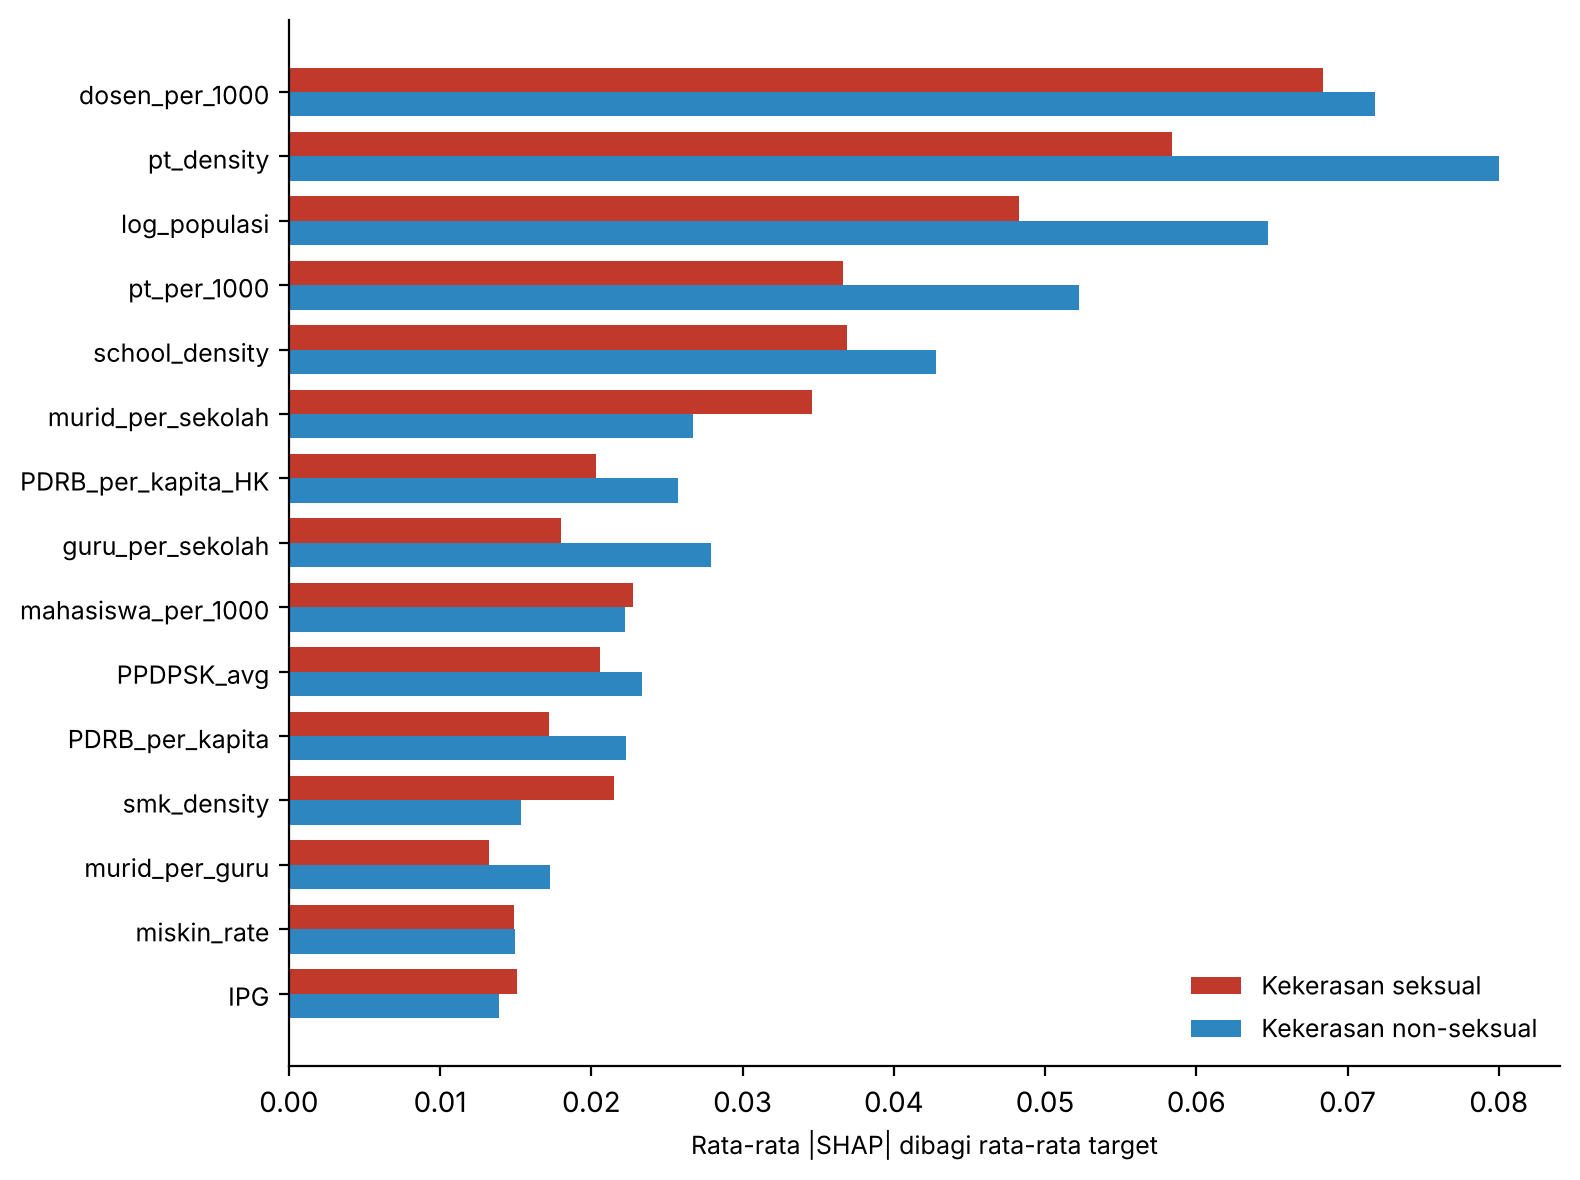

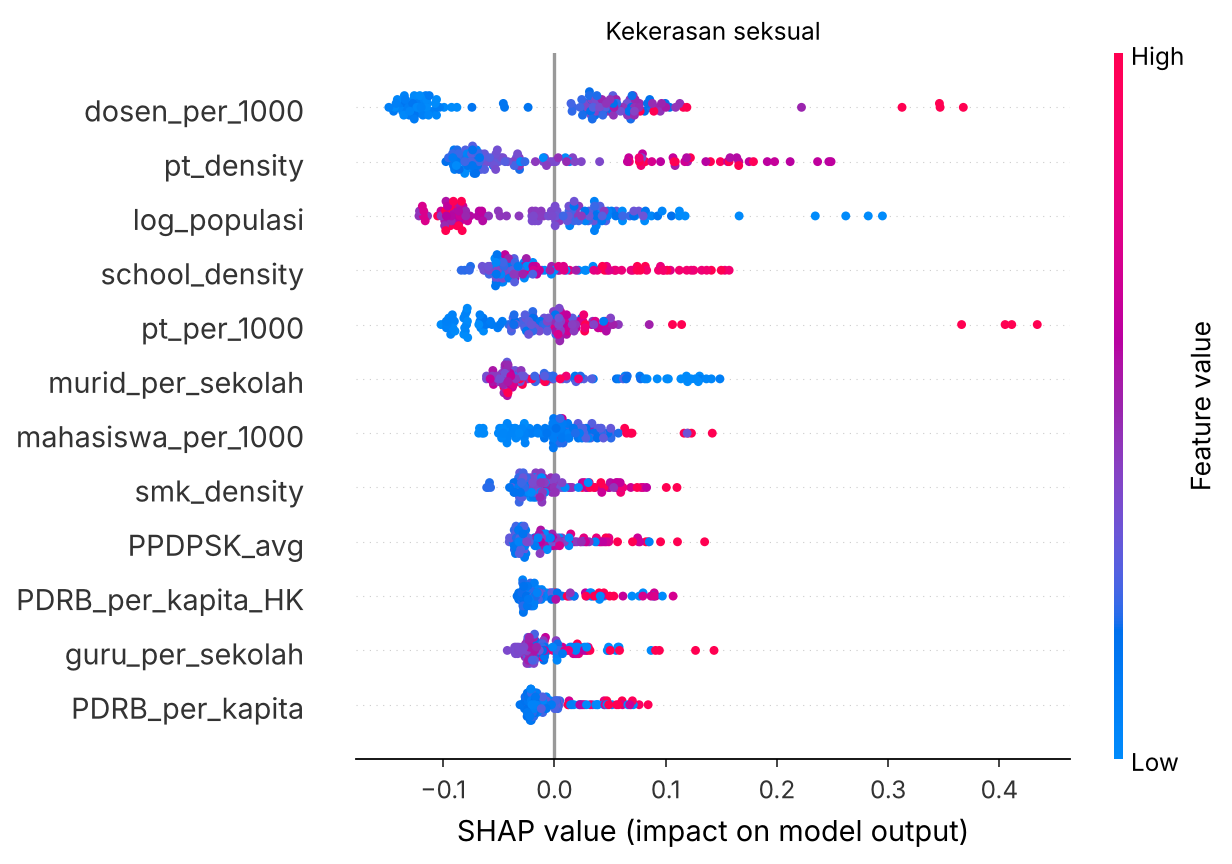

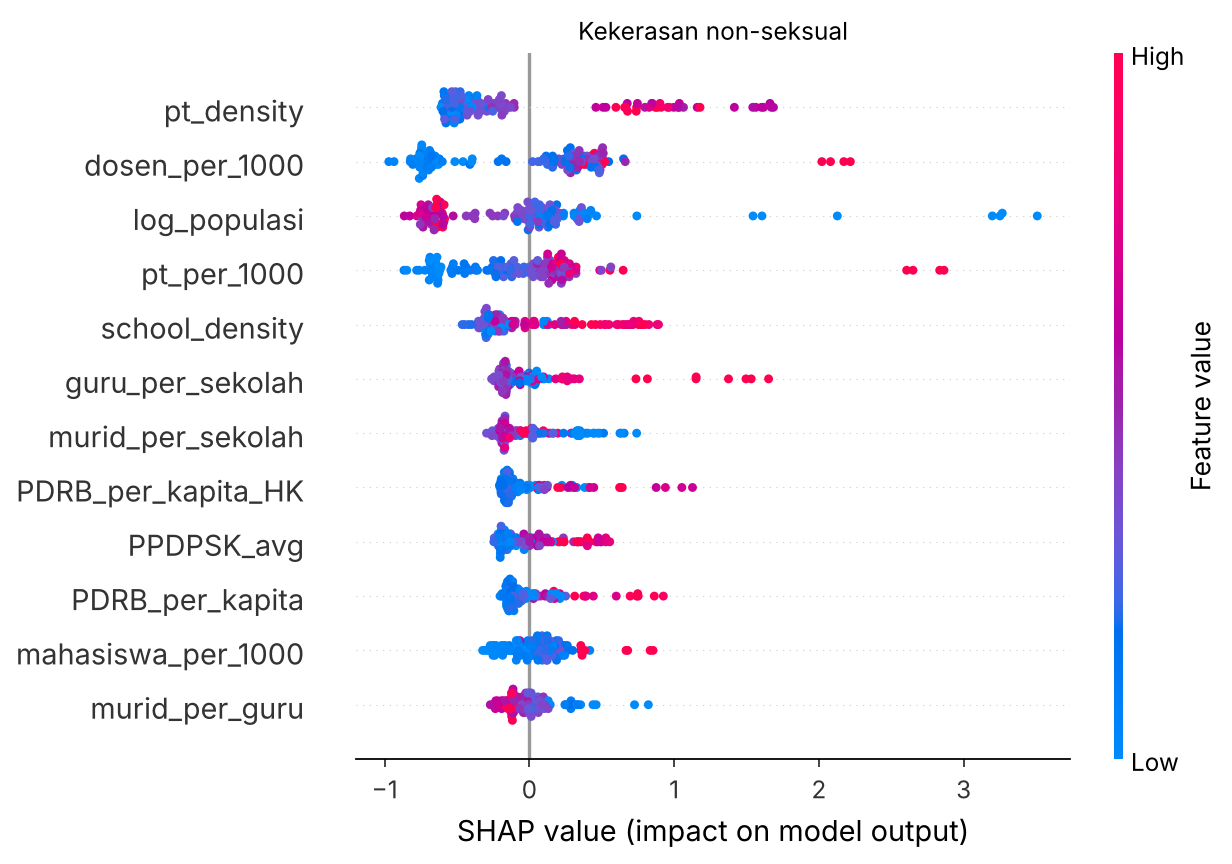

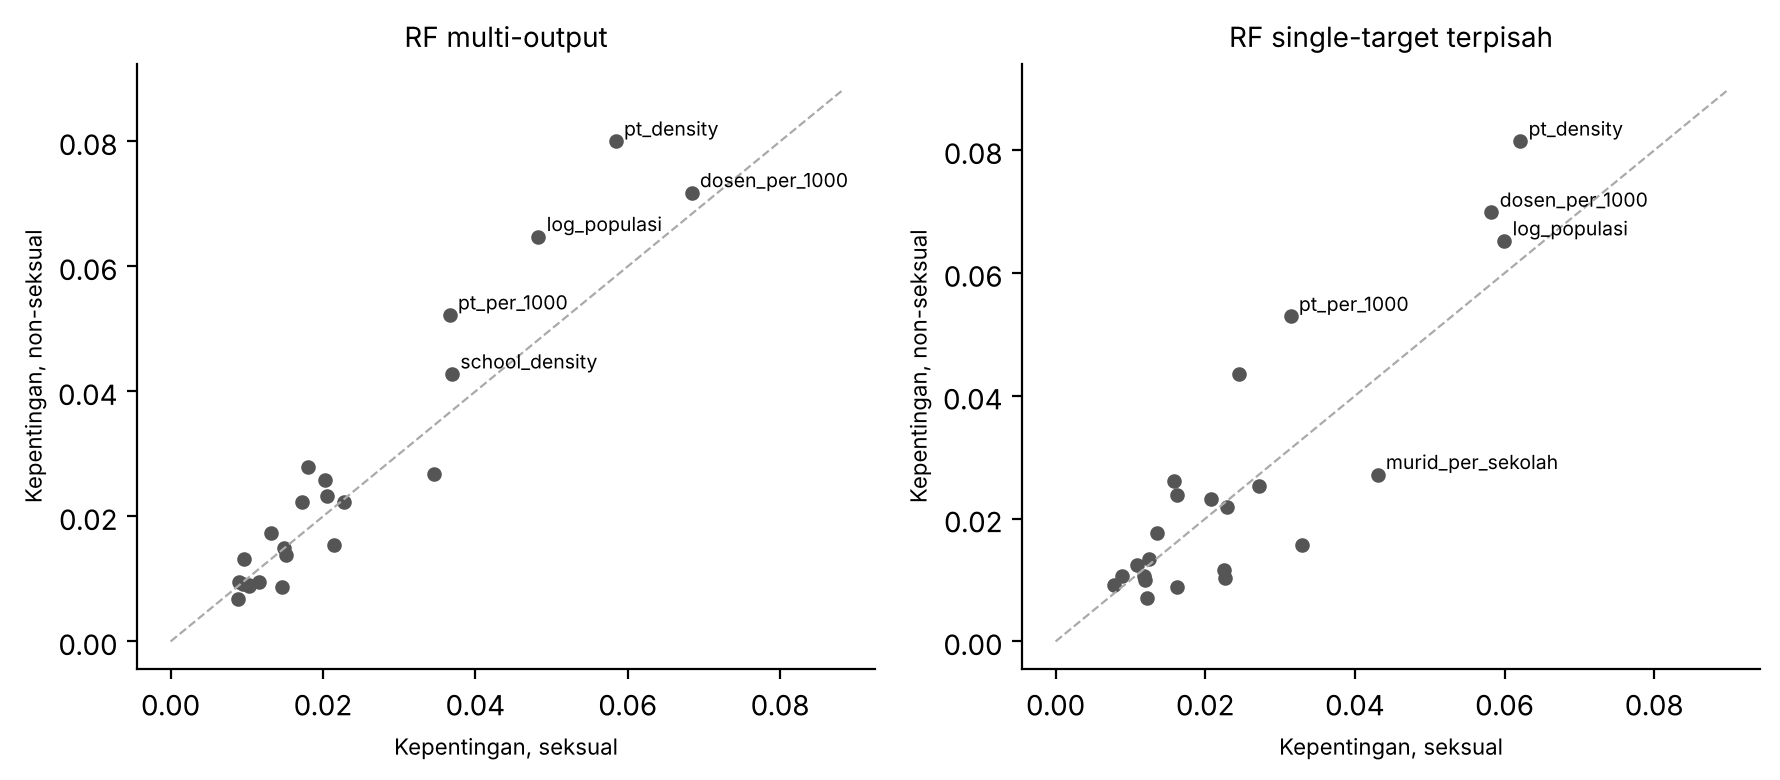

selesai


In [10]:
G = global_imp(SV_multi); G['tot'] = G.sum(1); G = G.sort_values('tot').tail(15)
fig, ax = plt.subplots(figsize=(8, 6), dpi=200); y = np.arange(len(G)); h = .38
ax.barh(y + h/2, G[TARGETS[0]], h, color='#C0392B', label='Kekerasan seksual')
ax.barh(y - h/2, G[TARGETS[1]], h, color='#2E86C1', label='Kekerasan non-seksual')
ax.set_yticks(y); ax.set_yticklabels(G.index, fontsize=9); ax.spines[['top', 'right']].set_visible(False)
ax.set_xlabel('Rata-rata |SHAP| dibagi rata-rata target', fontsize=9); ax.legend(frameon=False, fontsize=9, loc='lower right')
plt.tight_layout(); plt.savefig(f'{OUT}/fig_global.png'); plt.show()

for k, t in enumerate(TARGETS):
    plt.figure(dpi=160)
    shap.summary_plot(SV_multi[:, :, k], X_all, max_display=12, show=False, plot_size=(8, 5.5))
    plt.title(['Kekerasan seksual', 'Kekerasan non-seksual'][k], fontsize=11); plt.tight_layout()
    plt.savefig(f'{OUT}/fig_beeswarm_{t}.png', dpi=160); plt.show()

Gm, Gs = global_imp(SV_multi), global_imp(SV_single)
fig, axs = plt.subplots(1, 2, figsize=(9, 4), dpi=200)
for ax, Gx, ttl in [(axs[0], Gm, 'RF multi-output'), (axs[1], Gs, 'RF single-target terpisah')]:
    ax.scatter(Gx[TARGETS[0]], Gx[TARGETS[1]], s=18, color='#555')
    for f in Gx.sum(1).nlargest(5).index:
        ax.annotate(f, (Gx.loc[f, TARGETS[0]], Gx.loc[f, TARGETS[1]]), fontsize=7, xytext=(3, 2), textcoords='offset points')
    lim = max(Gx.max()) * 1.1; ax.plot([0, lim], [0, lim], ls='--', lw=.8, color='#aaa')
    ax.set_title(ttl, fontsize=10); ax.set_xlabel('Kepentingan, seksual', fontsize=8); ax.set_ylabel('Kepentingan, non-seksual', fontsize=8)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(f'{OUT}/fig_arsitektur.png'); plt.show()
print('selesai')

## 6. Ekspor data untuk dasbor Ruang Aman
Menghasilkan predictions.json (format dasbor) dan data_bersih_dasbor.csv.
Parameter Random Forest dikunci ke hasil Optuna yang dilaporkan di naskah, karena skor CV antar kandidat
parameter hampir sama (selisih < 0,001) sehingga Optuna bisa memilih kandidat berbeda di versi scikit-learn lain.

In [11]:
RF_WEB_PARAMS = dict(n_estimators=400, max_depth=10, min_samples_leaf=1, max_features='sqrt')
rf_web = RandomForestRegressor(random_state=SEED, n_jobs=-1, **RF_WEB_PARAMS).fit(train[SE_FEATURES], train[TARGETS])
web_rows = data.copy()
pred_web = rf_web.predict(web_rows[SE_FEATURES])
web_rows['pred_seksual'], web_rows['pred_non_seksual'] = pred_web[:, 0], pred_web[:, 1]
_expl = shap.TreeExplainer(rf_web)
sv_web = np.asarray(_expl.shap_values(web_rows[SE_FEATURES]))  # (n, f, 2)
BASE = np.ravel(_expl.expected_value)  # nilai dasar SHAP = rata-rata prediksi pada data latih
r2_web = {t: r2_score(test[t], rf_web.predict(test[SE_FEATURES])[:, k]) for k, t in enumerate(TARGETS)}
print('R2 uji 2024', {k: round(v, 3) for k, v in r2_web.items()})

# batas kelas = tertil angka observasi 2021-2023 per target, tetap untuk semua tahun
CUT = {t: train[t].quantile([1/3, 2/3]).values for t in TARGETS}
lvl = lambda v, t: 'low' if v <= CUT[t][0] else ('moderate' if v <= CUT[t][1] else 'high')

KODE = {'ACEH':'11','SUMATERA UTARA':'12','SUMATERA BARAT':'13','RIAU':'14','JAMBI':'15','SUMATERA SELATAN':'16',
        'BENGKULU':'17','LAMPUNG':'18','KEP. BANGKA BELITUNG':'19','KEP. RIAU':'21','DKI JAKARTA':'31','JAWA BARAT':'32',
        'JAWA TENGAH':'33','DI YOGYAKARTA':'34','JAWA TIMUR':'35','BANTEN':'36','BALI':'51','NUSA TENGGARA BARAT':'52',
        'NUSA TENGGARA TIMUR':'53','KALIMANTAN BARAT':'61','KALIMANTAN TENGAH':'62','KALIMANTAN SELATAN':'63',
        'KALIMANTAN TIMUR':'64','KALIMANTAN UTARA':'65','SULAWESI UTARA':'71','SULAWESI TENGAH':'72','SULAWESI SELATAN':'73',
        'SULAWESI TENGGARA':'74','GORONTALO':'75','SULAWESI BARAT':'76','MALUKU':'81','MALUKU UTARA':'82','PAPUA':'91','PAPUA BARAT':'92'}
LABEL = {'PDRB_per_kapita_HK':'PDRB per kapita (harga konstan)','PDRB_per_kapita':'PDRB per kapita',
         'PPKMLA':'PPKMLA','IPG':'Indeks Pembangunan Gender','miskin_rate':'Penduduk miskin',
         'ppm_rate':'Rasio penduduk miskin','tk_sekolah_per_1000':'Jumlah TK','tk_murid_per_1000':'Murid TK',
         'pt_per_1000':'Perguruan tinggi','dosen_per_1000':'Dosen','mahasiswa_per_1000':'Mahasiswa',
         'mahasiswa_per_PT':'Mahasiswa per kampus','dosen_per_PT':'Dosen per kampus',
         'murid_per_sekolah':'Murid per sekolah','guru_per_sekolah':'Guru per sekolah','murid_per_guru':'Murid per guru',
         'smk_density':'Kepadatan SMK','pt_density':'Kepadatan kampus','edu_index':'Indeks pendidikan',
         'RLS_gap':'Selisih lama sekolah','PPDPSK_avg':'PPDPSK','school_density':'Kepadatan sekolah',
         'log_populasi':'Jumlah penduduk'}


# nilai indikator yang ditampilkan di dasbor, beserta posisi relatif terhadap provinsi lain di tahun yang sama
def id_num(x, d=2):
    s = f'{x:,.{d}f}'.replace(',', '_').replace('.', ',').replace('_', '.')
    return s
def sig(x, n=2):
    from math import log10, floor
    if x == 0: return '0'
    d = max(0, n - 1 - floor(log10(abs(x))))
    return id_num(x, d)
def show_value(f, x):
    if f.startswith('PDRB'): return f'Rp{id_num(x / 1000, 1)} juta'
    if f == 'miskin_rate': return f'{id_num(x * 100, 1)}%'
    if f == 'log_populasi': return f'{id_num(np.exp(x) / 1e6, 2)} juta jiwa'
    if f == 'pt_per_1000': return f'{id_num(x * 100, 2)} per 100 rb penduduk'
    if f.endswith('_per_1000'): return f'{sig(x, 3)} per 1.000 penduduk'
    if f in ('IPG', 'edu_index', 'PPDPSK_avg', 'PPKMLA'): return id_num(x, 1)
    if abs(x) < 0.01: return sig(x, 2)
    return id_num(x, 2)
YEAR_VALUES = {y: g for y, g in web_rows.groupby('year')}
def explain(f, v, r):
    yv = YEAR_VALUES[int(r['year'])][f]
    x = float(r[f]); med = float(yv.median())
    pct = float((yv < x).mean() * 100)
    return {'feature': LABEL[f], 'contribution': round(float(v), 3),
            'value': round(x, 6), 'value_label': show_value(f, x), 'median_label': show_value(f, med),
            'percentile': round(pct), 'n_provinces': int(len(yv))}

records, flat = [], []
for i, (_, r) in enumerate(web_rows.reset_index(drop=True).iterrows()):
    rec = {'province_code': KODE[r['provinsi']], 'year': int(r['year'])}
    for k, (t, key) in enumerate([('rate_seksual', 'sexual'), ('rate_non_seksual', 'nonsexual')]):
        s = pd.Series(sv_web[i, :, k], index=SE_FEATURES)
        top = s.reindex(s.abs().sort_values(ascending=False).index)[:5]
        p = float(r[f'pred_{t[5:]}'])
        rec[key] = {'level': lvl(p, t), 'predicted_rate': round(p, 3), 'observed_rate': round(float(r[t]), 3),
                    'in_training': bool(r['tahun'] < 3), 'baseline_rate': round(float(BASE[k]), 3),
                    'explanations': [explain(f, v, r) for f, v in top.items()]}
    records.append(rec)
    flat.append(dict(province_code=rec['province_code'], provinsi=r['provinsi'], year=int(r['year']),
                     **{c: r[c] for c in SE_FEATURES}, rate_seksual=r['rate_seksual'], rate_non_seksual=r['rate_non_seksual'],
                     pred_seksual=r['pred_seksual'], pred_non_seksual=r['pred_non_seksual'],
                     kelas_seksual=rec['sexual']['level'], kelas_non_seksual=rec['nonsexual']['level'],
                     data_latih=r['tahun'] < 3))
# Papua dan Papua Barat 2024 tidak valid (pemekaran), dicatat sebagai tidak tersedia
for code in ['91', '92']:
    records.append({'province_code': code, 'year': 2024,
                    'sexual': {'level': 'unavailable', 'explanations': []},
                    'nonsexual': {'level': 'unavailable', 'explanations': []}})

from sklearn.metrics import f1_score
_t = web_rows[web_rows['tahun'] == 3]; _m = train.groupby('id')[TARGETS].mean()
F1 = {t: f1_score(_t[t].map(lambda v: lvl(v, t)), _t[f'pred_{t[5:]}'].map(lambda v: lvl(v, t)), average='macro') for t in TARGETS}
F1b = {t: f1_score(_t[t].map(lambda v: lvl(v, t)), _t['id'].map(_m[t]).map(lambda v: lvl(v, t)), average='macro') for t in TARGETS}
print('Macro-F1 kelas 2024', F1, 'baseline', F1b)
fmt = lambda x: f'{x:.2f}'.replace('.', ',')
methodology = (
    'Target adalah jumlah korban kekerasan seksual dan nonseksual (SIMFONI PPA) per 100.000 penduduk. '
    'Model Random Forest multi-output dilatih pada data 2021-2023 dengan 23 indikator sosial-ekonomi dan demografi (BPS), '
    'tanpa informasi kasus tahun sebelumnya. Nilai 2021-2023 adalah hasil model pada data latih, '
    f'sedangkan 2024 adalah data uji (R² {fmt(r2_web["rate_seksual"])} untuk seksual dan {fmt(r2_web["rate_non_seksual"])} untuk nonseksual). '
    f'Kesesuaian kelas risiko 2024 (Macro-F1) {fmt(F1["rate_seksual"])} dan {fmt(F1["rate_non_seksual"])}, '
    f'dibanding baseline rata-rata provinsi 2021-2023 sebesar {fmt(F1b["rate_seksual"])} dan {fmt(F1b["rate_non_seksual"])}. '
    'Baseline tersebut juga lebih akurat dalam R², dan kemampuan model untuk provinsi yang tidak dilihat saat pelatihan rendah, '
    'jadi hasil ini bersifat eksplanatori, bukan peramalan. '
    f'Kelas risiko memakai batas tertil angka observasi 2021-2023, yaitu seksual rendah ≤ {fmt(CUT["rate_seksual"][0])}, '
    f'tinggi > {fmt(CUT["rate_seksual"][1])}, nonseksual rendah ≤ {fmt(CUT["rate_non_seksual"][0])}, tinggi > {fmt(CUT["rate_non_seksual"][1])} per 100.000. '
    'Kontribusi fitur adalah nilai SHAP (TreeExplainer) dalam satuan korban per 100.000 penduduk, relatif terhadap rata-rata nasional, '
    'dan bukan hubungan sebab-akibat. Data mencatat kasus yang dilaporkan, sehingga angka tinggi dapat mencerminkan akses pelaporan yang lebih baik. '
    'Papua dan Papua Barat 2021-2023 memakai batas wilayah sebelum pemekaran. Data 2024 kedua provinsi serta empat provinsi baru di Papua belum tersedia.')
web_json = {'is_demo': False, 'model_version': 'rf-multioutput-se23-v1', 'input_period': '2021-2024 (BPS, SIMFONI PPA)',
            'methodology': methodology, 'class_cutoffs_per_100k': {t: [round(float(c), 3) for c in CUT[t]] for t in TARGETS},
            'predictions': records}
with open(f'{OUT}/predictions.json', 'w', encoding='utf-8') as fh:
    json.dump(web_json, fh, ensure_ascii=False, indent=1)
pd.DataFrame(flat).to_csv(f'{OUT}/data_bersih_dasbor.csv', index=False)
print(len(records), 'record', {t: CUT[t].round(3).tolist() for t in TARGETS})
print(pd.DataFrame(flat).groupby('year')[['kelas_seksual', 'kelas_non_seksual']].agg(lambda s: s.value_counts().to_dict()))

R2 uji 2024 {'rate_seksual': 0.573, 'rate_non_seksual': 0.791}


Macro-F1 kelas 2024 {'rate_seksual': 0.6977682811016145, 'rate_non_seksual': 0.8202380952380953} baseline {'rate_seksual': 0.7438271604938271, 'rate_non_seksual': 0.8197577276524645}
136 record {'rate_seksual': [0.73, 1.346], 'rate_non_seksual': [4.306, 8.217]}
                                kelas_seksual  \
year                                            
2021  {'moderate': 12, 'high': 12, 'low': 10}   
2022   {'moderate': 15, 'high': 12, 'low': 7}   
2023   {'moderate': 17, 'high': 11, 'low': 6}   
2024   {'moderate': 15, 'high': 11, 'low': 6}   

                            kelas_non_seksual  
year                                           
2021  {'high': 12, 'moderate': 11, 'low': 11}  
2022   {'moderate': 15, 'high': 11, 'low': 8}  
2023   {'moderate': 15, 'high': 11, 'low': 8}  
2024   {'moderate': 15, 'high': 10, 'low': 7}  


## 7. Single-target vs multi-target untuk ketiga model
Tiap keluarga model dibandingkan dalam dua versi.
- Multi-target (MT): satu model untuk dua target. RF multi-output, CatBoost MultiRMSE, MultiTaskElasticNet.
- Single-target (ST): dua model terpisah, satu per target.
Semua versi di-tuning dengan protokol yang sama (Optuna, GroupKFold per provinsi), kecuali RF-MT yang memakai
parameter terkunci di bagian 6 agar konsisten dengan angka yang dilaporkan.

In [12]:
from sklearn.linear_model import MultiTaskElasticNet
from sklearn.compose import TransformedTargetRegressor
from catboost import Pool
from numpy.linalg import norm

FAMILIES = ['RandomForest', 'CatBoost', 'ElasticNet']

def _space(fam, tr):
    if fam == 'ElasticNet':
        return dict(alpha=tr.suggest_float('alpha', 1e-3, 10, log=True), l1_ratio=tr.suggest_float('l1_ratio', 0.05, 1.0))
    return space(fam, tr)

def build(fam, prm, multi, seed=SEED):
    """Satu estimator. multi=True untuk dua target sekaligus, False untuk satu target."""
    if fam == 'RandomForest':
        return RandomForestRegressor(random_state=seed, n_jobs=-1, **prm)
    if fam == 'CatBoost':
        return CatBoostRegressor(loss_function='MultiRMSE' if multi else 'RMSE', random_seed=seed, verbose=0, thread_count=-1, **prm)
    # ElasticNet, target distandarkan agar kedua target berbobot sama pada penalti grup
    core = MultiTaskElasticNet if multi else ElasticNet
    reg = Pipeline([('sc', StandardScaler()), ('m', core(max_iter=50000, random_state=seed, **prm))])
    return TransformedTargetRegressor(regressor=reg, transformer=StandardScaler())

def shap_of(fam, est, X, multi):
    """Nilai SHAP berbentuk (n, f, 2) untuk multi, (n, f) untuk single."""
    if fam == 'RandomForest':
        return np.asarray(shap.TreeExplainer(est).shap_values(X))
    if fam == 'CatBoost':
        sv = est.get_feature_importance(Pool(X), type='ShapValues')
        return np.transpose(sv[:, :, :-1], (0, 2, 1)) if multi else sv[:, :-1]
    # ElasticNet, SHAP linear eksak dengan fitur independen = koefisien x (z - rata-rata z latih), dikali skala target
    reg = est.regressor_; z = reg.named_steps['sc'].transform(X)
    coef = np.atleast_2d(reg.named_steps['m'].coef_); ysd = np.atleast_1d(est.transformer_.scale_)
    sv = z[:, :, None] * (coef.T * ysd)[None, :, :]
    return sv if multi else sv[:, :, 0]

class Setup:
    """Membungkus versi MT atau ST agar keduanya punya predict dan shap berbentuk sama."""
    def __init__(self, fam, multi, prm):
        self.fam, self.multi, self.prm = fam, multi, prm
    def fit(self, X, Y, seed=SEED):
        if self.multi:
            self.models = [build(self.fam, self.prm, True, seed).fit(X, Y.values)]
        else:
            self.models = [build(self.fam, self.prm[k], False, seed).fit(X, Y.iloc[:, k].values) for k in range(2)]
        return self
    def predict(self, X):
        if self.multi: return self.models[0].predict(X)
        return np.column_stack([m.predict(X) for m in self.models])
    def shap(self, X):
        if self.multi: return shap_of(self.fam, self.models[0], X, True)
        return np.stack([shap_of(self.fam, m, X, False) for m in self.models], axis=2)

def tune_setup(fam, multi, X, Y, groups, k=None):
    def score(tr):
        prm = _space(fam, tr); sc = []
        for tri, vai in GroupKFold(n_splits=5).split(X, Y, groups):
            if multi:
                p = build(fam, prm, True).fit(X.iloc[tri], Y.iloc[tri].values).predict(X.iloc[vai])
                sc.append(np.mean([r2_score(Y.iloc[vai, j], p[:, j]) for j in range(2)]))
            else:
                p = build(fam, prm, False).fit(X.iloc[tri], Y.iloc[tri, k].values).predict(X.iloc[vai])
                sc.append(r2_score(Y.iloc[vai, k], p))
        return float(np.mean(sc))
    st = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    st.optimize(score, n_trials=N_TRIALS)
    return st.best_params, st.best_value

def ct_metrics(SV, ids_, base_):
    """Kemiripan penjelasan antara dua target."""
    G = pd.DataFrame({k: np.abs(SV[:, :, k]).mean(0) / base_[k] for k in range(2)}, index=SE_FEATURES)
    out = dict(spearman=spearmanr(G[0], G[1]).statistic, cosine=float(G[0] @ G[1] / (norm(G[0]) * norm(G[1]))))
    PS = [pd.DataFrame(SV[:, :, k], columns=SE_FEATURES).groupby(ids_).mean() for k in range(2)]
    jac = []
    for pid in PS[0].index:
        a = set(PS[0].loc[pid].abs().nlargest(3).index); b = set(PS[1].loc[pid].abs().nlargest(3).index)
        jac.append(len(a & b) / len(a | b))
    out.update(jaccard_top3=float(np.mean(jac)), identik_top3=int(np.sum(np.array(jac) == 1)))
    return out

Xtr, Ytr, gtr = train[SE_FEATURES], train[TARGETS], train['id']
X_eval, ids_eval = data[SE_FEATURES], data['id'].values
base_eval = data[TARGETS].mean().values
SETUP_PARAMS, cmp_rows, SV_store = {}, [], {}
for fam in FAMILIES:
    for multi in [True, False]:
        if fam == 'RandomForest' and multi:
            prm, cvs = RF_WEB_PARAMS, np.nan
        elif multi:
            prm, cvs = tune_setup(fam, True, Xtr, Ytr, gtr)
        else:
            res_ = [tune_setup(fam, False, Xtr, Ytr, gtr, k) for k in range(2)]
            prm, cvs = [r[0] for r in res_], float(np.mean([r[1] for r in res_]))
        SETUP_PARAMS[(fam, multi)] = prm
        s = Setup(fam, multi, prm).fit(Xtr, Ytr)
        P = s.predict(test[SE_FEATURES]); SV = s.shap(X_eval); SV_store[(fam, multi)] = SV
        row = dict(model=fam, versi='Multi-target' if multi else 'Single-target', CV_R2=cvs)
        for k, t in enumerate(TARGETS):
            row[f'R2_{t}'] = r2_score(test[t], P[:, k]); row[f'MAE_{t}'] = mean_absolute_error(test[t], P[:, k])
        row.update(ct_metrics(SV, ids_eval, base_eval))
        cmp_rows.append(row); print(row)
cmp_df = pd.DataFrame(cmp_rows); cmp_df.to_csv(f'{OUT}/single_vs_multi.csv', index=False)
json.dump({f'{k[0]}|{"MT" if k[1] else "ST"}': v for k, v in SETUP_PARAMS.items()}, open(f'{OUT}/parameter_single_vs_multi.json', 'w'), indent=1, default=str)
print(cmp_df.round(3).to_string())

{'model': 'RandomForest', 'versi': 'Multi-target', 'CV_R2': nan, 'R2_rate_seksual': 0.573318990022122, 'MAE_rate_seksual': 0.39536656199912595, 'R2_rate_non_seksual': 0.7909553109732805, 'MAE_rate_non_seksual': 1.5570629017031974, 'spearman': np.float64(0.9051383399209486), 'cosine': 0.9828467373478591, 'jaccard_top3': 0.6705882352941177, 'identik_top3': 14}


{'model': 'RandomForest', 'versi': 'Single-target', 'CV_R2': -0.055887175963718214, 'R2_rate_seksual': 0.45628490105232034, 'MAE_rate_seksual': 0.4402176234514562, 'R2_rate_non_seksual': 0.8010544112212237, 'MAE_rate_non_seksual': 1.5436313434203681, 'spearman': np.float64(0.7845849802371542), 'cosine': 0.9574136517602528, 'jaccard_top3': 0.5588235294117647, 'identik_top3': 8}


{'model': 'CatBoost', 'versi': 'Multi-target', 'CV_R2': -0.024339055503647046, 'R2_rate_seksual': 0.4062470472118458, 'MAE_rate_seksual': 0.4826308820365578, 'R2_rate_non_seksual': 0.7523830095066282, 'MAE_rate_non_seksual': 1.7491292115519168, 'spearman': np.float64(0.8310276679841897), 'cosine': 0.9595093746841822, 'jaccard_top3': 0.6558823529411765, 'identik_top3': 14}


{'model': 'CatBoost', 'versi': 'Single-target', 'CV_R2': -0.05146869592265707, 'R2_rate_seksual': 0.5054581006180174, 'MAE_rate_seksual': 0.4686662422173494, 'R2_rate_non_seksual': 0.8033101765726485, 'MAE_rate_non_seksual': 1.510735064026035, 'spearman': np.float64(0.5306324110671937), 'cosine': 0.8645474461311776, 'jaccard_top3': 0.5352941176470589, 'identik_top3': 9}


{'model': 'ElasticNet', 'versi': 'Multi-target', 'CV_R2': -0.047340532954819194, 'R2_rate_seksual': 0.22169325212107516, 'MAE_rate_seksual': 0.5318079982336992, 'R2_rate_non_seksual': 0.47679786315649375, 'MAE_rate_non_seksual': 2.433985277168927, 'spearman': np.float64(0.8300653594771243), 'cosine': 0.9532150006956375, 'jaccard_top3': 0.5588235294117647, 'identik_top3': 7}


{'model': 'ElasticNet', 'versi': 'Single-target', 'CV_R2': -0.047456237026796966, 'R2_rate_seksual': 0.14220767689537217, 'MAE_rate_seksual': 0.5529754575837309, 'R2_rate_non_seksual': 0.49703200475879117, 'MAE_rate_non_seksual': 2.385614451244409, 'spearman': np.float64(0.5985152643317044), 'cosine': 0.757866547437472, 'jaccard_top3': 0.4735294117647059, 'identik_top3': 4}
          model          versi  CV_R2  R2_rate_seksual  MAE_rate_seksual  R2_rate_non_seksual  MAE_rate_non_seksual  spearman  cosine  jaccard_top3  identik_top3
0  RandomForest   Multi-target    NaN            0.573             0.395                0.791                 1.557     0.905   0.983         0.671            14
1  RandomForest  Single-target -0.056            0.456             0.440                0.801                 1.544     0.785   0.957         0.559             8
2      CatBoost   Multi-target -0.024            0.406             0.483                0.752                 1.749     0.831   0.960    

## 8. Uji 2, bootstrap per provinsi
Provinsi data latih diambil ulang dengan pengembalian (cluster bootstrap), model MT dan ST dilatih ulang dengan
parameter dari bagian 7, lalu kemiripan penjelasan antartarget dihitung pada data evaluasi yang sama.
Hasilnya interval kepercayaan 95% untuk selisih kemiripan MT dikurangi ST.

In [13]:
N_BOOT = int(os.environ.get('N_BOOT', 200))
rng = np.random.default_rng(SEED)
prov_ids = np.sort(train['id'].unique())
boot = []
for b in range(N_BOOT):
    pick = rng.choice(prov_ids, size=len(prov_ids), replace=True)
    tb = pd.concat([train[train['id'] == p] for p in pick], ignore_index=True)
    for fam in FAMILIES:
        r = {}
        for multi in [True, False]:
            s = Setup(fam, multi, SETUP_PARAMS[(fam, multi)]).fit(tb[SE_FEATURES], tb[TARGETS], seed=SEED + b)
            m = ct_metrics(s.shap(X_eval), ids_eval, base_eval)
            for key in ['spearman', 'cosine', 'jaccard_top3']:
                r[f'{key}_{"MT" if multi else "ST"}'] = m[key]
        boot.append(dict(b=b, model=fam, **r))
    if b % 20 == 0: print('bootstrap', b)
boot_df = pd.DataFrame(boot); boot_df.to_csv(f'{OUT}/bootstrap.csv', index=False)
boot_sum = []
for fam in FAMILIES:
    d = boot_df[boot_df['model'] == fam]
    for key in ['spearman', 'cosine', 'jaccard_top3']:
        diff = d[f'{key}_MT'] - d[f'{key}_ST']
        boot_sum.append(dict(model=fam, metrik=key, MT=d[f'{key}_MT'].mean(), ST=d[f'{key}_ST'].mean(),
                             selisih=diff.mean(), CI_bawah=diff.quantile(0.025), CI_atas=diff.quantile(0.975),
                             proporsi_MT_lebih_mirip=(diff > 0).mean()))
boot_sum = pd.DataFrame(boot_sum); boot_sum.to_csv(f'{OUT}/bootstrap_ringkasan.csv', index=False)
print(boot_sum.round(3).to_string())

bootstrap 0


bootstrap 20


bootstrap 40


bootstrap 60


bootstrap 80


bootstrap 100


bootstrap 120


bootstrap 140


bootstrap 160


bootstrap 180


          model        metrik     MT     ST  selisih  CI_bawah  CI_atas  proporsi_MT_lebih_mirip
0  RandomForest      spearman  0.879  0.693    0.186     0.041    0.415                    0.990
1  RandomForest        cosine  0.973  0.897    0.076     0.013    0.197                    0.990
2  RandomForest  jaccard_top3  0.664  0.430    0.234     0.061    0.450                    0.985
3      CatBoost      spearman  0.823  0.525    0.298     0.035    0.572                    0.980
4      CatBoost        cosine  0.958  0.801    0.157     0.058    0.331                    0.995
5      CatBoost  jaccard_top3  0.660  0.377    0.284     0.103    0.526                    1.000
6    ElasticNet      spearman  0.845  0.470    0.375     0.166    0.651                    1.000
7    ElasticNet        cosine  0.916  0.727    0.189     0.063    0.337                    1.000
8    ElasticNet  jaccard_top3  0.592  0.387    0.205     0.023    0.365                    0.990


## 9. Uji 3, data sintetis dengan jawaban yang diketahui
Dua target dibangkitkan dari 23 fitur (saling berkorelasi 0,3). Faktor penyebabnya ditentukan sendiri.
- Sama: kedua target memakai x0, x1, x2.
- Sebagian: target A memakai x0, x1, x2, target B memakai x0, x3, x4.
- Berbeda: target A memakai x0, x1, x2, target B memakai x3, x4, x5.
Ukuran yang dilihat
- Kemiripan penjelasan antartarget dibanding kemiripan sebenarnya.
- Kebocoran, yaitu porsi kepentingan suatu target yang jatuh ke fitur milik target lain (seharusnya 0).
- Ketepatan tiga fitur teratas tiap target dibanding fitur penyebab sebenarnya.

In [14]:
NF = len(SE_FEATURES)
COMP = {0: lambda x: 2.0 * x, 1: lambda x: 1.5 * np.tanh(1.5 * x), 2: lambda x: x + 0.3 * x ** 3 / 3,
        3: lambda x: 2.0 * x, 4: lambda x: 1.5 * np.tanh(1.5 * x), 5: lambda x: x + 0.3 * x ** 3 / 3}
SCEN = {'Sama': ([0, 1, 2], [0, 1, 2]), 'Sebagian': ([0, 1, 2], [0, 3, 4]), 'Berbeda': ([0, 1, 2], [3, 4, 5])}
W_B = {0: 1.0, 1: 1.6, 2: 0.7, 3: 1.2, 4: 0.8, 5: 1.0}  # bobot target B, berbeda dari A agar tidak identik

def gen(n, scen, seed):
    r = np.random.default_rng(seed)
    C = np.full((NF, NF), 0.3); np.fill_diagonal(C, 1)
    X = r.multivariate_normal(np.zeros(NF), C, size=n)
    fa, fb = SCEN[scen]
    A = sum(COMP[j](X[:, j]) for j in fa); B = 5 * sum(W_B[j] * COMP[j](X[:, j]) for j in fb)
    A = A + r.normal(0, 0.6 * A.std(), n); B = B + r.normal(0, 0.6 * B.std(), n)
    return pd.DataFrame(X, columns=SE_FEATURES), pd.DataFrame({TARGETS[0]: A, TARGETS[1]: B})

def true_importance(scen):
    X, _ = gen(200000, scen, 0); fa, fb = SCEN[scen]
    ia, ib = np.zeros(NF), np.zeros(NF)
    for j in fa: c = COMP[j](X.iloc[:, j]); ia[j] = np.abs(c - c.mean()).mean()
    for j in fb: c = 5 * W_B[j] * COMP[j](X.iloc[:, j]); ib[j] = np.abs(c - c.mean()).mean()
    return ia, ib

SYN_N = [int(v) for v in os.environ.get('SYN_N', '100,300,1000,3000').split(',')]
SYN_SEEDS = int(os.environ.get('SYN_SEEDS', 5))
syn = []
for scen in SCEN:
    ia, ib = true_importance(scen); fa, fb = SCEN[scen]
    true_cos = float(ia @ ib / (norm(ia) * norm(ib)))
    only_a, only_b = sorted(set(fa) - set(fb)), sorted(set(fb) - set(fa))
    for n in SYN_N:
        for sd in range(SYN_SEEDS):
            Xs, Ys = gen(n, scen, 1000 + sd); Xe, _ = gen(500, scen, 9000 + sd)
            for fam in FAMILIES:
                for multi in [True, False]:
                    prm = SETUP_PARAMS[(fam, multi)]
                    s = Setup(fam, multi, prm).fit(Xs, Ys, seed=sd)
                    SV = s.shap(Xe); G = np.abs(SV).mean(0)  # (f, 2)
                    ga, gb = G[:, 0], G[:, 1]
                    row = dict(skenario=scen, n=n, seed=sd, model=fam, versi='MT' if multi else 'ST',
                               cos_estimasi=float(ga @ gb / (norm(ga) * norm(gb))), cos_sebenarnya=true_cos,
                               top3_A_benar=len(set(np.argsort(-ga)[:3]) & set(fa)) / 3,
                               top3_B_benar=len(set(np.argsort(-gb)[:3]) & set(fb)) / 3)
                    row['bias_kemiripan'] = row['cos_estimasi'] - true_cos
                    row['bocor_A'] = ga[only_b].sum() / ga.sum() if only_b else np.nan
                    row['bocor_B'] = gb[only_a].sum() / gb.sum() if only_a else np.nan
                    syn.append(row)
    print('skenario', scen, 'selesai')
syn_df = pd.DataFrame(syn); syn_df.to_csv(f'{OUT}/sintetis.csv', index=False)
syn_sum = syn_df.groupby(['skenario', 'n', 'model', 'versi'])[['cos_sebenarnya', 'cos_estimasi', 'bias_kemiripan', 'bocor_A', 'bocor_B', 'top3_A_benar', 'top3_B_benar']].mean().reset_index()
syn_sum.to_csv(f'{OUT}/sintetis_ringkasan.csv', index=False)
print(syn_sum.round(3).to_string())

skenario Sama selesai


skenario Sebagian selesai


skenario Berbeda selesai
    skenario     n         model versi  cos_sebenarnya  cos_estimasi  bias_kemiripan  bocor_A  bocor_B  top3_A_benar  top3_B_benar
0    Berbeda   100      CatBoost    MT           0.000         0.710           0.710    0.223    0.077         0.400         0.933
1    Berbeda   100      CatBoost    ST           0.000         0.251           0.251    0.052    0.074         0.933         0.933
2    Berbeda   100    ElasticNet    MT           0.000         0.415           0.415    0.090    0.125         0.933         0.933
3    Berbeda   100    ElasticNet    ST           0.000         0.096           0.096    0.000    0.068         0.933         0.933
4    Berbeda   100  RandomForest    MT           0.000         0.782           0.782    0.207    0.102         0.467         0.933
5    Berbeda   100  RandomForest    ST           0.000         0.424           0.424    0.074    0.097         0.933         0.867
6    Berbeda   300      CatBoost    MT           0.000    

In [15]:
# cek tambahan, apakah menstandarkan target menghilangkan kebocoran pada model pohon multi-target
cek = []
for fam in ['RandomForest', 'CatBoost']:
    for scale in [False, True]:
        for sd in range(3):
            Xs, Ys = gen(1000, 'Sebagian', 1000 + sd); Xe, _ = gen(500, 'Sebagian', 9000 + sd)
            Yf = (Ys - Ys.mean()) / Ys.std() if scale else Ys
            G = np.abs(Setup(fam, True, SETUP_PARAMS[(fam, True)]).fit(Xs, Yf, seed=sd).shap(Xe)).mean(0)
            cek.append(dict(model=fam, target_distandarkan=scale, cos=float(G[:, 0] @ G[:, 1] / (norm(G[:, 0]) * norm(G[:, 1]))),
                            bocor_A=G[[3, 4], 0].sum() / G[:, 0].sum(), bocor_B=G[[1, 2], 1].sum() / G[:, 1].sum()))
cek = pd.DataFrame(cek).groupby(['model', 'target_distandarkan']).mean(); cek.to_csv(f'{OUT}/cek_skala_target.csv'); print(cek.round(3))

                                    cos  bocor_A  bocor_B
model        target_distandarkan                         
CatBoost     False                0.827    0.188    0.025
             True                 0.749    0.111    0.102
RandomForest False                0.854    0.155    0.048
             True                 0.783    0.100    0.104
